# Clasificador de residuos con CNN (MobileNetV2 + TensorFlow Lite)

Este cuaderno entrena un modelo que clasifica fotos de residuos en 6 categorías (`cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`) y lo exporta a un archivo `.tflite` para usarlo después en una app Android.

## Antes de empezar

1. **Activa la GPU:** menú *Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU > Guardar*. Hazlo ahora, porque al cambiarla el entorno se reinicia.
2. **Verifica que `archive.zip`** (el ZIP que descargaste de Kaggle) esté en la raíz de **Mi unidad** en tu Google Drive.
3. **Ejecuta las celdas en orden**, una por una (Shift + Enter). Debajo de cada celda de código hay una explicación de lo que hace.

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs disponibles:", gpus)
if not gpus:
    print("ATENCIÓN: no hay GPU. Actívala en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")

TensorFlow: 2.21.0
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Qué hace:** importa TensorFlow (la librería con la que se construye y entrena la red neuronal) y comprueba si Colab te asignó una GPU.

**Qué deberías ver:** una lista con un dispositivo, algo como `[PhysicalDevice(name='/physical_device:GPU:0', ...)]`. Si sale `[]`, la GPU no está activada. El entrenamiento igual funciona sin GPU, pero será mucho más lento.

In [ ]:
from google.colab import drive
import glob, zipfile, os

drive.mount("/content/drive")

zips = sorted(glob.glob("/content/drive/MyDrive/archive*.zip"))
if not zips:
    raise FileNotFoundError("No encontré archive.zip en Mi unidad. Súbelo a la raíz de tu Google Drive y vuelve a ejecutar esta celda.")
ZIP_PATH = zips[0]
print("Usando:", ZIP_PATH)

EXTRACT_DIR = "/content/residuos"
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)
print("Descomprimido en:", EXTRACT_DIR)

Mounted at /content/drive
Usando: /content/drive/MyDrive/archive.zip
Descomprimido en: /content/residuos


**Qué hace:** conecta tu Google Drive con Colab (te pedirá permiso, acéptalo), busca el archivo `archive.zip` en *Mi unidad* y lo descomprime dentro de Colab (`/content/residuos`).

**Por qué así:** copiar las ~2,500 fotos sueltas a Colab desde Drive es lento. Es mucho más rápido subir un solo ZIP y descomprimirlo aquí, en el disco local de Colab.

**Nota:** los archivos en `/content` se borran cuando se cierra la sesión de Colab. Eso no es problema, porque el ZIP sigue en tu Drive y el modelo final lo guardaremos en Drive al terminar.

In [ ]:
DATA_DIR = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if "cardboard" in dirs:
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError("No encontré la carpeta con las categorías (cardboard, glass, ...).")

clases = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Ruta del dataset:", DATA_DIR)

total = 0
for c in clases:
    n = len(os.listdir(os.path.join(DATA_DIR, c)))
    total += n
    print(f"{c:10s} {n}")
print("Total de imágenes:", total)

assert len(clases) == 6, f"Se esperaban 6 clases y encontré {len(clases)}: {clases}"

Ruta del dataset: /content/residuos/garbage classification/Garbage classification
cardboard  403
glass      501
metal      410
paper      594
plastic    482
trash      137
Total de imágenes: 2527


**Qué hace:** busca dentro de lo descomprimido la carpeta que contiene directamente las 6 categorías, y cuenta cuántas fotos hay en cada una. No tienes que escribir ninguna ruta a mano.

**Qué deberías ver:** las 6 clases con estas cantidades aproximadas: `cardboard` 403, `glass` 501, `metal` 410, `paper` 594, `plastic` 482 y `trash` 137, con un total cercano a 2,527. La última línea (`assert`) detiene el cuaderno con un mensaje claro si no hay exactamente 6 clases.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)   # tamaño de entrada que espera MobileNetV2
BATCH_SIZE = 32         # imágenes procesadas por cada paso de entrenamiento
SEED = 42               # semilla para que la división sea reproducible

# 80% entrenamiento, 20% para validación + prueba
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="both",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)
class_names = train_ds.class_names
print("Clases:", class_names)

# Dividimos el 20% restante por la mitad: 10% validación y 10% prueba
n_val_batches = tf.data.experimental.cardinality(val_ds).numpy()
test_ds = val_ds.take(n_val_batches // 2)
val_ds = val_ds.skip(n_val_batches // 2)

print("Lotes -> entrenamiento:", train_ds.cardinality().numpy(),
      "| validación:", val_ds.cardinality().numpy(),
      "| prueba:", test_ds.cardinality().numpy())

Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Using 505 files for validation.
Clases: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Lotes -> entrenamiento: 64 | validación: 8 | prueba: 8


**Qué hace:** lee las fotos directamente de las carpetas (cada carpeta es una clase), las redimensiona a 224×224 píxeles y las agrupa en lotes de 32. Luego las divide en tres grupos:

- **Entrenamiento (80%):** con estas fotos la red aprende.
- **Validación (10%):** sirve para vigilar durante el entrenamiento si la red está aprendiendo bien o solo memorizando.
- **Prueba (10%):** fotos que la red nunca ve mientras entrena. Se usan al final para medir cuánta precisión tendrá en el mundo real.

**Importante:** la precisión que importa es la de **prueba**, no la de entrenamiento.

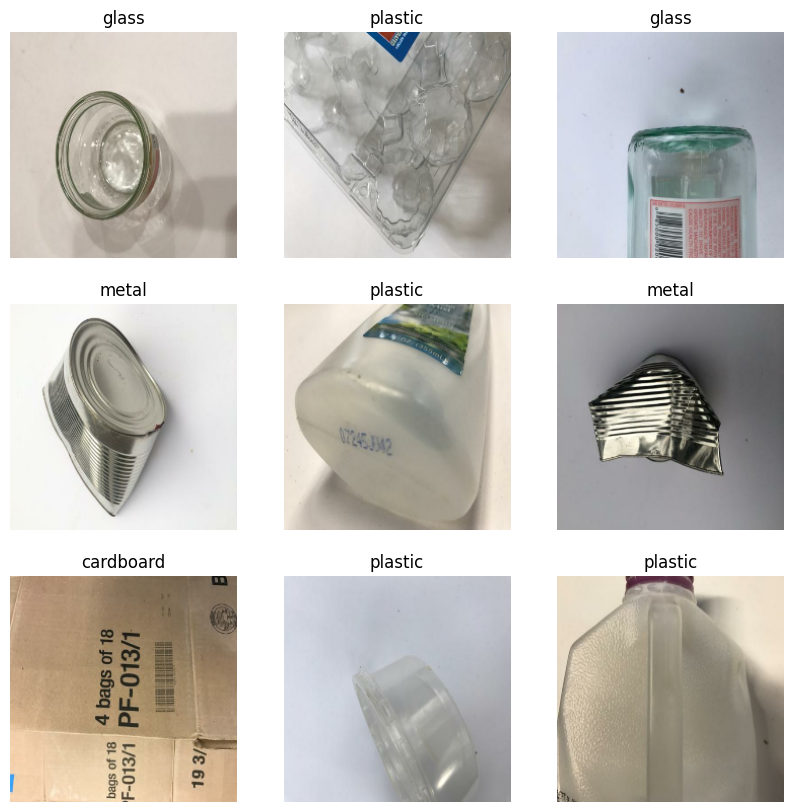

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.show()

**Qué hace:** muestra 9 fotos de ejemplo con su etiqueta. Sirve para confirmar con tus propios ojos que las imágenes se cargaron bien y que cada etiqueta corresponde a lo que se ve.

In [ ]:
train_labels = np.concatenate([y.numpy() for _, y in train_ds])
counts = np.bincount(train_labels, minlength=len(class_names))
class_weight = {i: float(counts.sum() / (len(class_names) * c)) for i, c in enumerate(counts)}

for i, name in enumerate(class_names):
    print(f"{name:10s} imágenes: {counts[i]:4d}   peso: {class_weight[i]:.2f}")

cardboard  imágenes:  334   peso: 1.01
glass      imágenes:  399   peso: 0.84
metal      imágenes:  322   peso: 1.05
paper      imágenes:  471   peso: 0.72
plastic    imágenes:  393   peso: 0.86
trash      imágenes:  103   peso: 3.27


**Qué hace:** el dataset está desbalanceado (hay mucho más `paper` que `trash`). Si no hacemos nada, la red tendería a ignorar las clases con pocas fotos. Aquí calculamos un **peso por clase**: las clases con menos fotos reciben un peso mayor, así que equivocarse en ellas cuesta más durante el entrenamiento.

**Qué deberías ver:** `trash` con el peso más alto (cerca de 3) y `paper` con el más bajo (cerca de 0.7).

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

**Qué hace:** aplica **aumento de datos** solo a las fotos de entrenamiento: las voltea, las rota, les hace zoom y les cambia el contraste de forma aleatoria. Así la red ve cada foto "distinta" en cada ronda y aprende a reconocer el residuo sin depender de una posición o luz exacta. Es clave con un dataset pequeño.

`prefetch` prepara el siguiente lote mientras la GPU procesa el actual, para que no haya tiempos muertos.

Validación y prueba **no** llevan aumento, porque ahí queremos medir con las fotos tal cual son.

In [ ]:
# Base: MobileNetV2 ya entrenada con millones de imágenes (ImageNet)
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False   # por ahora la dejamos congelada

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)   # pasa de 0-255 a -1...1
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Qué hace:** construye la red con **transfer learning**: en vez de entrenar una CNN desde cero (que necesitaría decenas de miles de fotos), reutilizamos **MobileNetV2**, una CNN que ya aprendió a ver bordes, texturas y formas con millones de imágenes, y solo le añadimos una "cabeza" nueva para nuestras 6 clases.

Las capas, en orden:
- **Rescaling:** convierte los píxeles de 0-255 al rango -1 a 1 que MobileNetV2 espera. Está dentro del modelo a propósito, para que en Android no tengas que normalizar nada.
- **MobileNetV2:** extrae las características de la imagen (congelada por ahora).
- **GlobalAveragePooling2D:** resume esas características en un vector.
- **Dropout(0.3):** apaga el 30% de las neuronas al azar al entrenar, para evitar que memorice.
- **Dense(6, softmax):** da la probabilidad de cada una de las 6 clases.

`model.summary()` imprime la tabla de capas. Verás que casi todos los parámetros están como "no entrenables" (la base congelada); solo se entrenan unos 7,700 de la cabeza.

In [ ]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 45s 492ms/step - accuracy: 0.4862 - loss: 1.3441 - val_accuracy: 0.7430 - val_loss: 0.7083
Epoch 2/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 368ms/step - accuracy: 0.7023 - loss: 0.8334 - val_accuracy: 0.7912 - val_loss: 0.5981
Epoch 3/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 22s 344ms/step - accuracy: 0.7394 - loss: 0.7357 - val_accuracy: 0.8434 - val_loss: 0.5120
Epoch 4/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 339ms/step - accuracy: 0.7740 - loss: 0.6502 - val_accuracy: 0.8353 - val_loss: 0.4981
Epoch 5/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 22s 340ms/step - accuracy: 0.7908 - loss: 0.5915 - val_accuracy: 0.8554 - val_loss: 0.4857
Epoch 6/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 341ms/step - accuracy: 0.7859 - loss: 0.5642 - val_accuracy: 0.8554 - val_loss: 0.4381
Epoch 7/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 345ms/step - accuracy: 0.8037 - loss: 0.5588 - val_accuracy: 0.8474 - val_loss: 0.4527
Epoch 8/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 22s 338ms/step - accuracy: 0.8150 - loss: 0.5001 - val_accu

**Qué hace:** primera fase de entrenamiento. Solo se entrena la cabeza nueva, mientras MobileNetV2 sigue congelada. Cada *epoch* es una pasada completa por todas las fotos de entrenamiento.

**Cómo leer la salida:** `accuracy` es la precisión sobre las fotos de entrenamiento y `val_accuracy` es la de validación. Lo que más importa es `val_accuracy`: debería subir hasta rondar 85-92%.

**EarlyStopping:** si `val_accuracy` no mejora en 3 epochs seguidos, el entrenamiento se detiene solo y se restauran los mejores pesos. Por eso puede terminar antes de las 12 epochs. Dura unos pocos minutos con GPU.

In [ ]:
# Descongelamos solo las últimas 30 capas de MobileNetV2
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Velocidad de aprendizaje mucho más baja para no "romper" lo que ya sabe
model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)],
)

Epoch 1/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 55s 523ms/step - accuracy: 0.7344 - loss: 0.8185 - val_accuracy: 0.8835 - val_loss: 0.4275
Epoch 2/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 348ms/step - accuracy: 0.7695 - loss: 0.6587 - val_accuracy: 0.8795 - val_loss: 0.4285
Epoch 3/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 347ms/step - accuracy: 0.7755 - loss: 0.6431 - val_accuracy: 0.8715 - val_loss: 0.4282
Epoch 4/12
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 345ms/step - accuracy: 0.7789 - loss: 0.6003 - val_accuracy: 0.8755 - val_loss: 0.4238


**Qué hace:** segunda fase, el **ajuste fino** (*fine-tuning*). Descongelamos las últimas 30 capas de MobileNetV2 para que se adapten un poco a fotos de residuos (que son distintas a las de ImageNet) y seguimos entrenando.

**Por qué la velocidad de aprendizaje es tan baja (`1e-5`):** esas capas ya saben mucho. Con pasos grandes las "desordenaríamos"; con pasos pequeños solo se afinan.

**Qué pasó en esta ejecución:** `val_accuracy` se mantuvo cerca del 88%, igual que al final de la primera fase, y el EarlyStopping detuvo esta fase tras 4 epochs. Es decir, el ajuste fino no mejoró el resultado con este dataset. Es un resultado válido: se restauran los mejores pesos de esta fase y se sigue con el modelo.

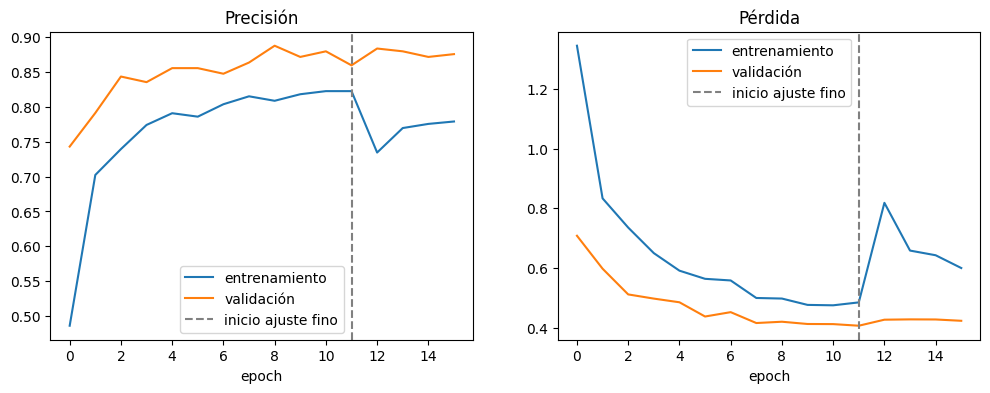

In [ ]:
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]
inicio_ajuste = len(history1.history["accuracy"]) - 1

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="entrenamiento")
plt.plot(val_acc, label="validación")
plt.axvline(inicio_ajuste, color="gray", linestyle="--", label="inicio ajuste fino")
plt.title("Precisión")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="entrenamiento")
plt.plot(val_loss, label="validación")
plt.axvline(inicio_ajuste, color="gray", linestyle="--", label="inicio ajuste fino")
plt.title("Pérdida")
plt.xlabel("epoch")
plt.legend()

plt.show()

**Qué hace:** grafica cómo evolucionaron la precisión y la pérdida (el "error") durante todo el entrenamiento. La línea punteada marca dónde empezó el ajuste fino.

**Cómo interpretarlo:**
- Las curvas de entrenamiento y validación deberían ir juntas y bastante cerca.
- Si la de entrenamiento sube mucho y la de validación se queda abajo y separada, la red está **memorizando** (sobreajuste).

Precisión en el conjunto de prueba: 81.64%

              precision    recall  f1-score   support

   cardboard      0.846     0.892     0.868        37
       glass      0.817     0.875     0.845        56
       metal      0.837     0.804     0.820        51
       paper      0.898     0.815     0.854        54
     plastic      0.727     0.800     0.762        40
       trash      0.667     0.556     0.606        18

    accuracy                          0.816       256
   macro avg      0.799     0.790     0.793       256
weighted avg      0.818     0.816     0.816       256



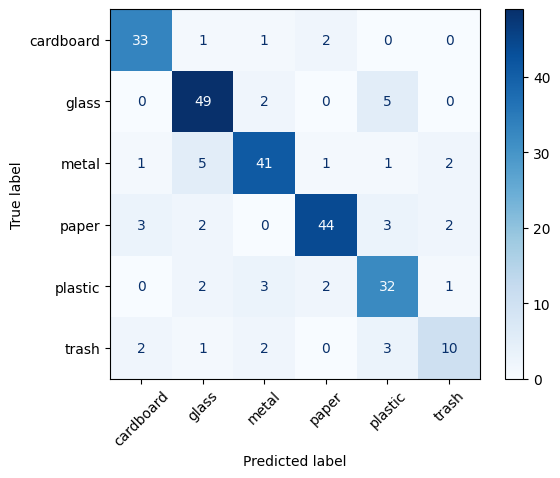

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Precisión en el conjunto de prueba: {test_acc:.2%}\n")

y_true, y_pred = [], []
for x, y in test_ds:
    p = model.predict(x, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(p, axis=1))

indices = list(range(len(class_names)))
print(classification_report(y_true, y_pred, labels=indices, target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=indices)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45, cmap="Blues")
plt.show()

**Qué hace:** mide el modelo con las fotos de **prueba**, las que nunca vio. Esa es la precisión realista que puedes esperar.

**Cómo leer los resultados:**
- **Precisión en prueba:** el porcentaje general de aciertos sobre fotos que el modelo nunca vio. Es la cifra realista a reportar (en esta ejecución: 81.64%, es decir, 209 de 256 fotos).
- **Tabla (classification_report):** para cada clase, *precision* (de lo que dijo que era X, cuánto realmente lo era), *recall* (de todo lo que era X, cuánto encontró) y *f1-score* (el balance de ambos). Espera que `trash` sea la clase más débil, porque tiene muy pocas fotos.
- **Matriz de confusión:** las filas son la clase real y las columnas lo que predijo el modelo. Lo ideal es una diagonal fuerte. Los números fuera de la diagonal son las confusiones (por ejemplo, `glass` con `plastic`, o `paper` con `cardboard`).

**Nota:** con solo ~250 fotos de prueba, el resultado puede variar un par de puntos si cambias la semilla.

In [ ]:
SAVE_DIR = "/content/drive/MyDrive/residuos_modelo"
os.makedirs(SAVE_DIR, exist_ok=True)

try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
except Exception as e:
    print("La conversión directa falló, usando SavedModel. Motivo:", e)
    model.export("/content/saved_model_residuos")
    converter = tf.lite.TFLiteConverter.from_saved_model("/content/saved_model_residuos")
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()

tflite_path = os.path.join(SAVE_DIR, "modelo_residuos.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_model)

labels_path = os.path.join(SAVE_DIR, "labels.txt")
with open(labels_path, "w") as f:
    f.write("\n".join(class_names))

model.save(os.path.join(SAVE_DIR, "modelo_residuos.keras"))

print(f"Modelo TFLite guardado en: {tflite_path}")
print(f"Tamaño: {len(tflite_model) / 1e6:.2f} MB")
print("Etiquetas guardadas en:", labels_path)
print("Orden de las clases:", class_names)

Saved artifact at '/tmp/tmpuk9cqdyg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_159')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  134542973927248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972301776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972299472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972293712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972300624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972289680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972302736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972302544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972302928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134542972301584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1345429723

**Qué hace:** convierte el modelo entrenado a **TensorFlow Lite** (`.tflite`), el formato ligero para correr en celulares, y guarda tres archivos en tu Drive, en la carpeta `residuos_modelo`:

- `modelo_residuos.tflite`: el que irá dentro de la app Android.
- `labels.txt`: los nombres de las clases, uno por línea, en el **orden exacto** en que el modelo da sus resultados. La app lo usará para mostrar "plastic" en vez de "posición 4".
- `modelo_residuos.keras`: el modelo completo, por si después quieres reentrenarlo o mejorarlo.

`Optimize.DEFAULT` comprime el modelo (cuantización) para que pese menos, alrededor de 2.5-3 MB, con casi ninguna pérdida de precisión.

El bloque `try/except` es un respaldo: si la conversión directa falla por diferencias entre versiones de TensorFlow, usa el camino alternativo vía SavedModel.

In [ ]:
try:
    interpreter = tf.lite.Interpreter(model_content=tflite_model)
except Exception:
    # En versiones nuevas de TensorFlow el intérprete vive en otro paquete
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ai-edge-litert"], check=True)
    from ai_edge_litert.interpreter import Interpreter
    interpreter = Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
print("Entrada:", inp["shape"], inp["dtype"])
print("Salida: ", out["shape"], out["dtype"])

correctas, total = 0, 0
for x, y in test_ds:
    for img, label in zip(x.numpy(), y.numpy()):
        interpreter.set_tensor(inp["index"], np.expand_dims(img, 0).astype(np.float32))
        interpreter.invoke()
        pred = int(np.argmax(interpreter.get_tensor(out["index"])[0]))
        correctas += int(pred == label)
        total += 1

print(f"Precisión del modelo TFLite en prueba: {correctas / total:.2%} ({total} imágenes)")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Entrada: [  1 224 224   3] <class 'numpy.float32'>
Salida:  [1 6] <class 'numpy.float32'>
Precisión del modelo TFLite en prueba: 81.64% (256 imágenes)


**Qué hace:** carga el archivo `.tflite` recién creado y lo prueba con las mismas fotos de prueba, igual que lo hará la app Android. Así confirmas que la conversión no dañó el modelo antes de llevarlo a Android Studio.

**Qué deberías ver:** una entrada de forma `[1, 224, 224, 3]` tipo `float32`, una salida de forma `[1, 6]`, y una precisión casi idéntica (idealmente la misma, con diferencias de hasta 1 punto) a la de la celda de evaluación. Si TensorFlow te avisa que `tf.lite.Interpreter` está obsoleto, es solo un aviso y no afecta el resultado.

## Resumen para la app Android

Cuando pases a Android Studio, tendrás que respetar estos datos del modelo:

| Dato | Valor |
|---|---|
| Archivo | `modelo_residuos.tflite` (colócalo en `app/src/main/assets`) |
| Tamaño de entrada | 224 × 224 píxeles, 3 canales (RGB) |
| Tipo de entrada | `float32`, con los píxeles en el rango **0 a 255** (el modelo normaliza internamente) |
| Salida | 6 probabilidades que suman 1 |
| Orden de las clases | el de `labels.txt` (alfabético: cardboard, glass, metal, paper, plastic, trash) |

Descarga `modelo_residuos.tflite` y `labels.txt` desde la carpeta `residuos_modelo` de tu Google Drive. Con eso pasamos a la parte de Android Studio.